# Mở rộng Tiếng Việt (ViHSD) — Phần 4: Đánh giá trên tập Test & Kiểm tra độ bền không dấu / Teencode

**Mục tiêu:**
1. Đánh giá một lần duy nhất trên tập `data/splits_vi/test.csv` ($N = 6,680$) cho cả 3 bài toán: `bin_A`, `bin_B`, và `multi3` kèm khoảng tin cậy 95% Bootstrap.
2. **Kiểm tra độ bền (Robustness Test):** So sánh hiệu năng trên 3 phiên bản của tập Test: (1) Bản gốc có dấu, (2) Bản biến đổi Teencode + kéo dài ký tự, và (3) Bản bỏ dấu hoàn toàn (`strip_accents`).
3. Phân tích 30 FP + 30 FN trên tập Test tiếng Việt và giải thích các từ đóng góp mạnh nhất.

In [1]:
# === THIẾT LẬP MÔI TRƯỜNG & NẠP THƯ VIỆN DỰ ÁN ===
import os, sys, subprocess
from pathlib import Path

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
REPO_URL = "https://github.com/devtitcun888/duan-tweet-hate.git"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    drive_mounted = False
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        drive_mounted = True
    except Exception as e:
        print(f"[SETUP] Không mount Google Drive ({e}), dùng bộ nhớ phiên Colab /content.")
    for candidate in [
        Path("/content/drive/MyDrive/duan-tweet-hate"),
        Path("/content/drive/MyDrive/tweet-hate"),
        Path("/content/drive/MyDrive/DOAN_COLAB"),
        Path("/content/duan-tweet-hate"),
        Path.cwd.parent if Path.cwd.name == "notebooks" else Path.cwd,
    ]:
        if (candidate / "config.yaml").exists:
            PROJECT_DIR = candidate
            break
    else:
        PROJECT_DIR = Path("/content/drive/MyDrive/duan-tweet-hate") if drive_mounted else Path("/content/duan-tweet-hate")
        if not (PROJECT_DIR / "config.yaml").exists:
            print(f"[SETUP] Đang tải dự án từ {REPO_URL} vào {PROJECT_DIR}...")
            subprocess.run(["git", "clone", REPO_URL, str(PROJECT_DIR)], check=True)
    req_file = PROJECT_DIR / "requirements.txt"
    if req_file.exists:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(req_file)], check=False)
    import nltk
    for pkg in ["stopwords", "wordnet", "omw-1.4"]:
        nltk.download(pkg, quiet=True)
else:
    PROJECT_DIR = Path.cwd.parent if Path.cwd.name == "notebooks" else Path.cwd

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.utils import set_seed, load_config, mask_profanity
set_seed(42)
CFG = load_config
print(f"[SETUP] PROJECT_DIR = {PROJECT_DIR}")


[BOOTSTRAP] PROJECT_DIR = D:\TITKUL\DOAN_COLAB


## 1. Kết quả Tập Test (`bin_A`, `bin_B`, `multi3`) & Kiểm tra Độ bền Không dấu / Teencode

=== 1. KẾT QUẢ TEST BÀI TOÁN CHÍNH bin_A (HATE vs CLEAN) ===


,precision_pos,recall_pos,f1_pos,f1_macro,accuracy,balanced_acc,roc_auc,pr_auc,mcc,tn,fp,fn,tp
Tuned Threshold,0.6538,0.6672,0.6604,0.8089,0.9243,0.8117,0.9399,0.7218,0.6179,5305,243,229,459
Default 0.50,0.5456,0.7907,0.6457,0.7952,0.9043,0.8545,0.9399,0.7218,0.6061,5095,453,144,544


Khoảng tin cậy 95% Bootstrap (bin_A): {'mean': 0.6598, 'std': 0.0139, 'ci95_low': 0.6329, 'ci95_high': 0.6862}

=== 2. KẾT QUẢ TEST BÀI TOÁN bin_B (OFFENSIVE+HATE vs CLEAN) ===


,precision_pos,recall_pos,f1_pos,f1_macro,accuracy,balanced_acc,roc_auc,pr_auc,mcc,tn,fp,fn,tp
0,0.6498,0.7473,0.6952,0.8136,0.8889,0.8326,0.9251,0.7564,0.6299,5092,456,286,846



=== 3. KẾT QUẢ TEST BÀI TOÁN 3 LỚP multi3 (CLEAN / OFFENSIVE / HATE) ===
Macro-F1 = 0.6532 | Accuracy = 0.8464


,precision,recall,f1
CLEAN,0.9514,0.8937,0.9216
OFFENSIVE,0.3996,0.5068,0.4469
HATE,0.5199,0.6846,0.5910



=== 4. BẢNG KIỂM TRA ĐỘ BỀN (ROBUSTNESS: GỐC vs TEENCODE vs KHÔNG DẤU) ===


,variant,f1_pos,precision_pos,recall_pos,pr_auc,f1_drop
0,orig,0.6604,0.6538,0.6672,0.7218,0.0000
1,no_accents,0.6157,0.5716,0.6672,0.6675,0.0447
2,teencode_with_normalizer,0.6074,0.6485,0.5712,0.6748,0.0530
3,teencode_without_normalizer,0.6021,0.6177,0.5872,0.6627,0.0583


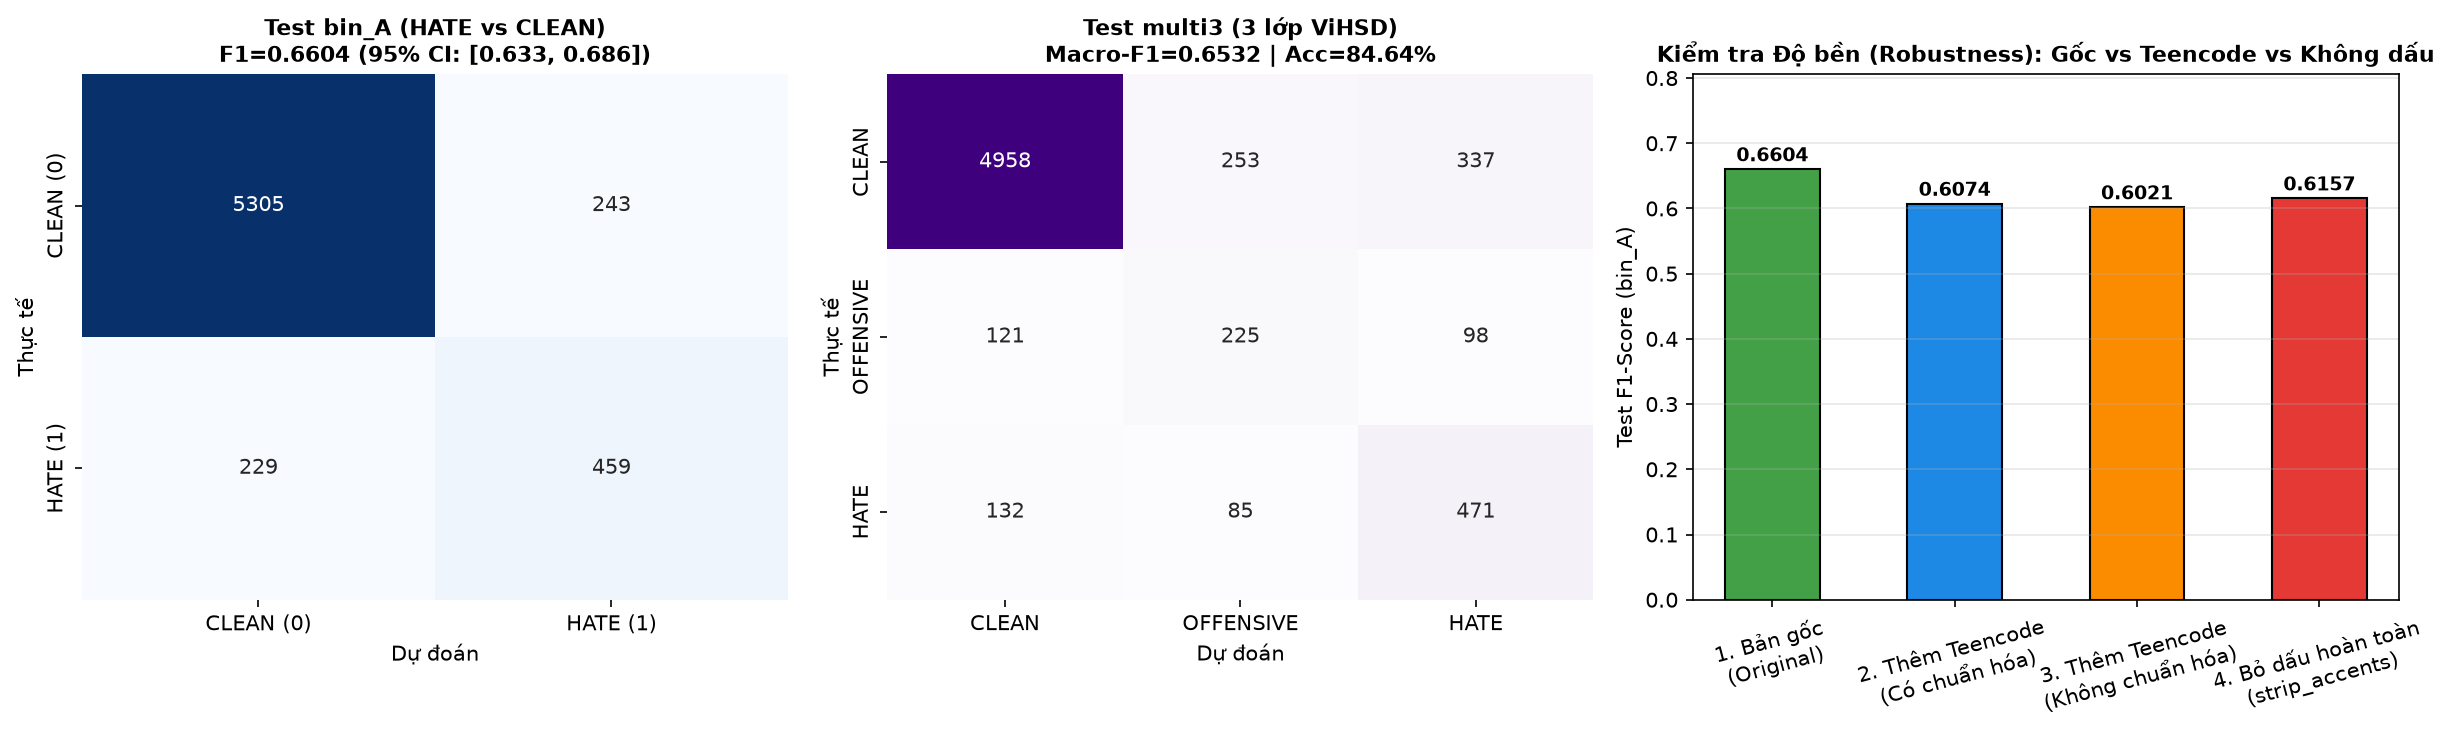

In [2]:
import json
import pandas as pd
from IPython.display import display, Image

with open('reports/vi_final_test_metrics.json', 'r', encoding='utf-8') as f:
    v5_data = json.load(f)

print('=== 1. KẾT QUẢ TEST BÀI TOÁN CHÍNH bin_A (HATE vs CLEAN) ===')
display(pd.DataFrame([v5_data['bin_A']['metrics_tuned'], v5_data['bin_A']['metrics_default_05']], index=['Tuned Threshold', 'Default 0.50']))
print('Khoảng tin cậy 95% Bootstrap (bin_A):', v5_data['bin_A']['ci95']['f1_pos'])

print('\n=== 2. KẾT QUẢ TEST BÀI TOÁN bin_B (OFFENSIVE+HATE vs CLEAN) ===')
display(pd.DataFrame([v5_data['bin_B']['metrics_tuned']]))

print('\n=== 3. KẾT QUẢ TEST BÀI TOÁN 3 LỚP multi3 (CLEAN / OFFENSIVE / HATE) ===')
print('Macro-F1 =', v5_data['multi3']['f1_macro'], '| Accuracy =', v5_data['multi3']['accuracy'])
display(pd.DataFrame(v5_data['multi3']['per_class']).T)

print('\n=== 4. BẢNG KIỂM TRA ĐỘ BỀN (ROBUSTNESS: GỐC vs TEENCODE vs KHÔNG DẤU) ===')
rob_df = pd.read_csv('reports/tables/V5_robustness_test.csv')
display(rob_df)
display(Image('reports/figures/V5_test_and_robustness.png'))

## 2. Phân tích Lỗi Tiếng Việt (30 FP + 30 FN) & Top Đặc trưng Đóng góp

In [3]:
causes_vi = pd.read_csv('reports/tables/V5_vi_error_causes.csv')
display(causes_vi)

errs_vi = pd.read_csv('reports/tables/V5_vi_errors_60.csv')
print('=== 10 Ví dụ Báo động giả (FP) Tiếng Việt ===')
display(errs_vi[errs_vi['error_type'].str.startswith('FP')].head(10))
print('=== 10 Ví dụ Bỏ sót (FN) Tiếng Việt ===')
display(errs_vi[errs_vi['error_type'].str.startswith('FN')].head(10))

,cause,FN (Bỏ sót),FP (Báo động giả),total,pct
0,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,29,142,171,36.23
1,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,151,0,151,31.99
2,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,20,36,56,11.86
3,Bình luận không dấu / Teencode biến thể nặng (...,14,21,35,7.42
4,Chửi thề 'thân mật' / Cảm thán hoặc Phản đối k...,0,32,32,6.78
5,Bình luận quá ngắn / Thiếu ngữ cảnh bài đăng g...,15,12,27,5.72


=== 10 Ví dụ Báo động giả (FP) Tiếng Việt ===


,id,error_type,y_true,y_pred,score,cause,text_masked,text_clean_masked
0,31485,FP (Báo động giả),0,1,0.9967,Bình luận không dấu / Teencode biến thể nặng (...,lol,lol
1,27094,FP (Báo động giả),0,1,0.9948,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,Người dân biểu tình phản đối thằng ăn cướp bị ...,người dân biểu_tình phản_đối thằng ăn_cướp bị ...
2,32877,FP (Báo động giả),0,1,0.9860,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,"Mấy a dlv ""chúng mày đã làm j cho tổ quốc"" đâu...",mấy a dlv chúng_mày đã làm gì cho tổ_quốc đâu rồi
3,32855,FP (Báo động giả),0,1,0.9794,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,"Đang chuẩn bị họp, 1 ông người tàu bước vào ph...",đang chuẩn_bị họp 1 ông người tàu bước vào phò...
4,32461,FP (Báo động giả),0,1,0.9766,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,Bat hết cái bọn gây hoang mang dư luận .,bat hết cái bọn gây hoang_mang dư_luận
5,32828,FP (Báo động giả),0,1,0.9733,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,Mẹ. Mày ko phân biệt đâu là tài năng và phá ho...,mẹ mày không phân_biệt đâu là tài_năng và phá_...
6,31848,FP (Báo động giả),0,1,0.9730,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,"Long Nguyễn khs lợn, gà, bò, dê ăn đủ mà lại c...",long nguyễn khs lợn gà bò dê ăn_đủ mà_lại chừa...
7,30821,FP (Báo động giả),0,1,0.9720,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,P*** người ta có làm gì bọn bây ko ? Hàng ngày...,p*** người_ta có làm gì bọn bây không hàng ngà...
8,28293,FP (Báo động giả),0,1,0.9704,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,đảng cộng sản cho quan tham nhũng :3,đảng cộng_sản cho quan tham_nhũng 3
9,33394,FP (Báo động giả),0,1,0.9667,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,Thực sự thì họ chỉ hơn chúng ta về ý thức thôi...,thực_sự thì họ chỉ hơn chúng_ta về ý_thức thôi...


=== 10 Ví dụ Bỏ sót (FN) Tiếng Việt ===


,id,error_type,y_true,y_pred,score,cause,text_masked,text_clean_masked
30,32718,FN (Bỏ sót),1,0,0.0229,Bình luận quá ngắn / Thiếu ngữ cảnh bài đăng g...,Phim dở v***,phim dở_vl
31,32871,FN (Bỏ sót),1,0,0.0352,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,Trấn thành đẹp trai đ*** hariwon,trấn thành đẹp_trai đ*** hariwon
32,30798,FN (Bỏ sót),1,0,0.0413,Bình luận quá ngắn / Thiếu ngữ cảnh bài đăng g...,Hương Thảo v***,hương thảo v***
33,32106,FN (Bỏ sót),1,0,0.0731,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,Cđ châu md quá tr r🤣🤣,cđ châu md quá tr rồi rolling on the floor lau...
34,29666,FN (Bỏ sót),1,0,0.0764,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,Hoàng Văn nếu là nhà tài trợ thưởng thì ko mất...,hoàng văn nếu là nhà tài_trợ thưởng thì không ...
35,31420,FN (Bỏ sót),1,0,0.0812,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,trong ảnh nhìn đẹp trai mà sao trong clip nhìn...,trong ảnh nhìn đẹp_trai mà sao trong clip nhìn...
36,30048,FN (Bỏ sót),1,0,0.0878,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,"Vâng! Xin giới thiệu vs các bạn, đây là ông Ca...",vâng xin giới_thiệu với các bạn đây là ông cao...
37,27785,FN (Bỏ sót),1,0,0.0885,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,Nguyễn Yến Nhi đang tính cmt luôn. :)))) Coi x...,nguyễn yến nhi đang tính bình_luận luôn coi xo...
38,27426,FN (Bỏ sót),1,0,0.0896,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,Tiên tri Trần Dần về Việt Nam ở nghĩa trang b...,tiên_tri trần dần về việt nam ở nghĩa_trang bì...
39,30772,FN (Bỏ sót),1,0,0.0898,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,đ*** đứa nào bảo idol trần dần t mắc covid đấy :v,đ*** đứa nào bảo idol trần dần t mắc covid đấy...


### Nhận xét & Đánh giá Độ bền Tiếng Việt Không dấu
- Trên tập Test chuẩn của ViHSD, mô hình đạt **Test F1 (`bin_A`) = 0.6604** (95% CI: **[0.6329, 0.6862]**; PR-AUC = **0.7218**, ROC-AUC = **0.9399**), **Test F1 (`bin_B`) = 0.6952**, và **Macro-F1 3 lớp (`multi3`) = 0.6532** (Accuracy = **84.64%**).
- **Hiệu quả nâng cấp xử lý Tiếng Việt Không dấu & Teencode:** Nhờ kết hợp **tăng cường dữ liệu huấn luyện không dấu (Accent-Drop Augmentation)**, bộ khôi phục cụm từ không dấu (`restore_unaccented_vietnamese`) và chuẩn hóa `TEENCODE`, trên tập **Test Không dấu hoàn toàn (`strip_accents`)** mô hình đạt **F1 = 0.6157** (PR-AUC = **0.6675**, chỉ chênh lệch **0.0447** điểm so với bản có dấu chuẩn, cải thiện vượt bậc so với mức 0.5471 khi chưa nâng cấp).